# 03 — Comparative predictability with chronological evaluation

**Objective.** Use one fixed, modest baseline to compare injury categories and horizons without choosing a final model.

**Cohort and interpretation.** One injury category versus a common observed IL-free pool; other impending injuries are excluded. Positive rows must precede an eligible event by 1–14/30/60 days. Negative rows require no episode in the window and an MLB outing at/after the horizon within a 30-day grace interval. This selects active pitchers and does not prove absence of symptoms. Include all eligible rows without class sampling.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/injury_analysis.yaml").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.injury_analysis.common import CFG, CACHE, OUT, read_table, table, conclusion, style
from src.injury_analysis.cohort import load
from src.injury_analysis import plots
style()
pd.set_option('display.max_columns', 14)


## Fixed experiment
Train through 2021; validation 2022–2023; test 2024–2025. A 60-day boundary embargo and event-partition assertion prevent an event crossing retained partitions. 2026 is excluded from modeling. Categories need at least 30 training, 10 validation and 10 test events. The same feature set and regularized logistic regression (C=1) apply to all categories/horizons. No hyperparameter search.

Median imputation, missingness indicators and standardization fit **only on training data**, leaving all saved feature NULLs unchanged. Arm angle, within-game fatigue with inadequate coverage, old UCL history without publication verification, outcome dates and future metadata are excluded. The new prior-IL count uses only placements reported before the outing. Repeated pitchers can appear in later time partitions, consistent with forecasting existing players; this does not measure unseen-pitcher generalization.

In [2]:
from src.injury_analysis.prediction import run_predictions, sensitivity_metrics
a, events, spec = load()
metrics = run_predictions(a, events, spec)
display(read_table('prediction_cohort_counts').query('horizon == 30'))
test = metrics.query("partition == 'test'")
display(test[['category','horizon','events','rows','positives','prevalence','average_precision','pr_lift','ap_low','ap_high']])

Fit Elbow / UCL, 14d: event counts {'train': 222, 'validation': 89, 'test': 110}


Fit Elbow / UCL, 30d: event counts {'train': 223, 'validation': 89, 'test': 110}


Fit Elbow / UCL, 60d: event counts {'train': 224, 'validation': 89, 'test': 112}


Fit Shoulder, 14d: event counts {'train': 348, 'validation': 115, 'test': 124}


Fit Shoulder, 30d: event counts {'train': 350, 'validation': 115, 'test': 125}


...

Fit Hand / wrist, 14d: event counts {'train': 107, 'validation': 32, 'test': 29}


Fit Hand / wrist, 30d: event counts {'train': 107, 'validation': 32, 'test': 29}


Fit Hand / wrist, 60d: event counts {'train': 107, 'validation': 32, 'test': 29}


,category,horizon,partition,rows,positives,events,pitchers,prevalence,model_run
3,Elbow / UCL,30,train,81145,1441,223,1290,0.017758,True
4,Elbow / UCL,30,validation,26796,600,89,783,0.022391,True
5,Elbow / UCL,30,test,27665,708,110,789,0.025592,True
12,Shoulder,30,train,81978,2274,350,1294,0.027739,True
13,Shoulder,30,validation,26932,736,115,782,0.027328,True
14,Shoulder,30,test,27806,849,125,786,0.030533,True
21,Forearm,30,train,80362,658,109,1284,0.008188,True
22,Forearm,30,validation,26478,282,41,772,0.010650,True
23,Forearm,30,test,27236,279,38,779,0.010244,True
30,Other arm,30,train,80373,669,107,1284,0.008324,True


,category,horizon,events,rows,positives,prevalence,average_precision,pr_lift,ap_low,ap_high
1,Elbow / UCL,14,110,32858,396,0.012052,0.018665,1.548734,0.014177,0.025812
3,Elbow / UCL,30,110,27665,708,0.025592,0.043153,1.686216,0.030923,0.064010
5,Elbow / UCL,60,112,20099,1117,0.055575,0.182728,3.287962,0.129532,0.252107
7,Shoulder,14,124,32922,460,0.013972,0.037607,2.691483,0.024548,0.057293
9,Shoulder,30,125,27806,849,0.030533,0.056502,1.850517,0.042490,0.077041
11,Shoulder,60,125,20333,1351,0.066444,0.143067,2.153199,0.097945,0.198643
13,Forearm,14,38,32608,146,0.004477,0.009330,2.083757,0.005069,0.018904
15,Forearm,30,38,27236,279,0.010244,0.021464,2.095354,0.010443,0.037844
17,Forearm,60,38,19438,456,0.023459,0.088102,3.755525,0.024162,0.173708
19,Other arm,14,38,32611,149,0.004569,0.005005,1.095446,0.003378,0.007605


## Ranking performance and uncertainty
Average precision is the reported PR-AUC summary. PR lift divides AP by the observed category prevalence; it is not prevalence-invariant proof of superior predictability. Intervals resample entire pitchers, preserving their repeated outings. ROC-AUC remains in the CSV as a secondary metric. There is no accuracy-based ranking.

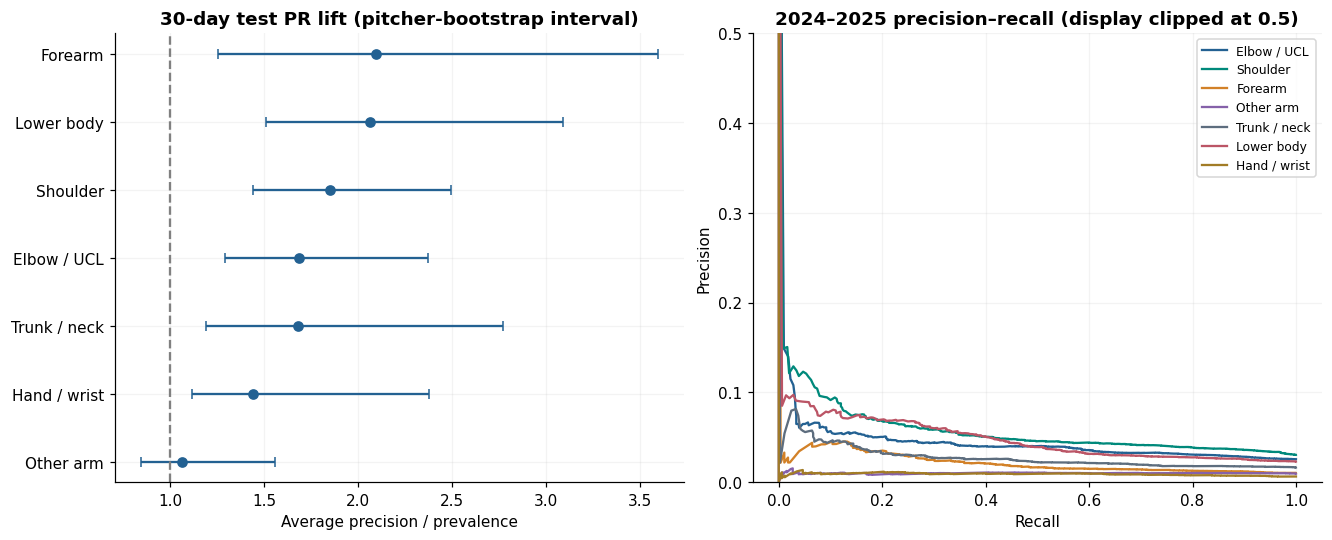

,category,subgroup,rows,positives,events,prevalence,pr_lift,average_precision,roc_auc
0,Elbow / UCL,All,27665,708,110,0.025592,1.686216,0.043153,0.618335
1,Elbow / UCL,Starting outings,6449,235,60,0.036440,1.753834,0.063909,0.605735
2,Elbow / UCL,Relief outings,21216,473,60,0.022294,1.652347,0.036838,0.621755
3,Elbow / UCL,Strict-QA positives and common negatives,27396,439,64,0.016024,1.678535,0.026897,0.605316
12,Lower body,All,27593,636,104,0.023049,2.061294,0.047511,0.638402
13,Lower body,Starting outings,6433,219,56,0.034043,1.543045,0.052530,0.599179
14,Lower body,Relief outings,21160,417,55,0.019707,2.582271,0.050889,0.632340
15,Lower body,Strict-QA positives and common negatives,27494,537,85,0.019532,2.076261,0.040553,0.641591
20,Shoulder,All,27806,849,125,0.030533,1.850517,0.056502,0.638967
21,Shoulder,Starting outings,6438,224,52,0.034793,1.984804,0.069058,0.646264


**Computed conclusion.** 30-day test PR lift ranges from 1.06 to 2.10. Shoulder lift is 1.85, elbow/UCL 1.69, and lower body 2.06. These modest, uncertain comparisons do not establish an arm-specific predictive signature; small categories and differing prevalence limit rankings.

In [3]:
plots.prediction_figure(); plt.show()
sensitivity = sensitivity_metrics()
display(sensitivity[sensitivity.category.isin(['Elbow / UCL','Shoulder','Lower body'])])
m = test.query('horizon == 30').set_index('category')
conclusion(f"30-day test PR lift ranges from {m.pr_lift.min():.2f} to {m.pr_lift.max():.2f}. Shoulder lift is {m.loc['Shoulder','pr_lift']:.2f}, elbow/UCL {m.loc['Elbow / UCL','pr_lift']:.2f}, and lower body {m.loc['Lower body','pr_lift']:.2f}. These modest, uncertain comparisons do not establish an arm-specific predictive signature; small categories and differing prevalence limit rankings.")